# Hedging Lab

In [1]:
#read the parquet file
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date
from scipy.stats import norm
from scipy.interpolate import PchipInterpolator
from pathlib import Path
from functions import *


Data file: mes_donnees.csv
Estimated correlation rho: 0.99
--- PRICING RESULTS (6 JANUARY 2020) ---
Basket Forward price (F_avg): 61.36 $
Global basket volatility (v): 0.2224
Theoretical Asian Call price at 78$: 1.0962 $
Exact Put strike for Zero-Cost Collar: 44.17 $
Verification - Call Price: 1.0962 $ | Put Price: 1.0963 $


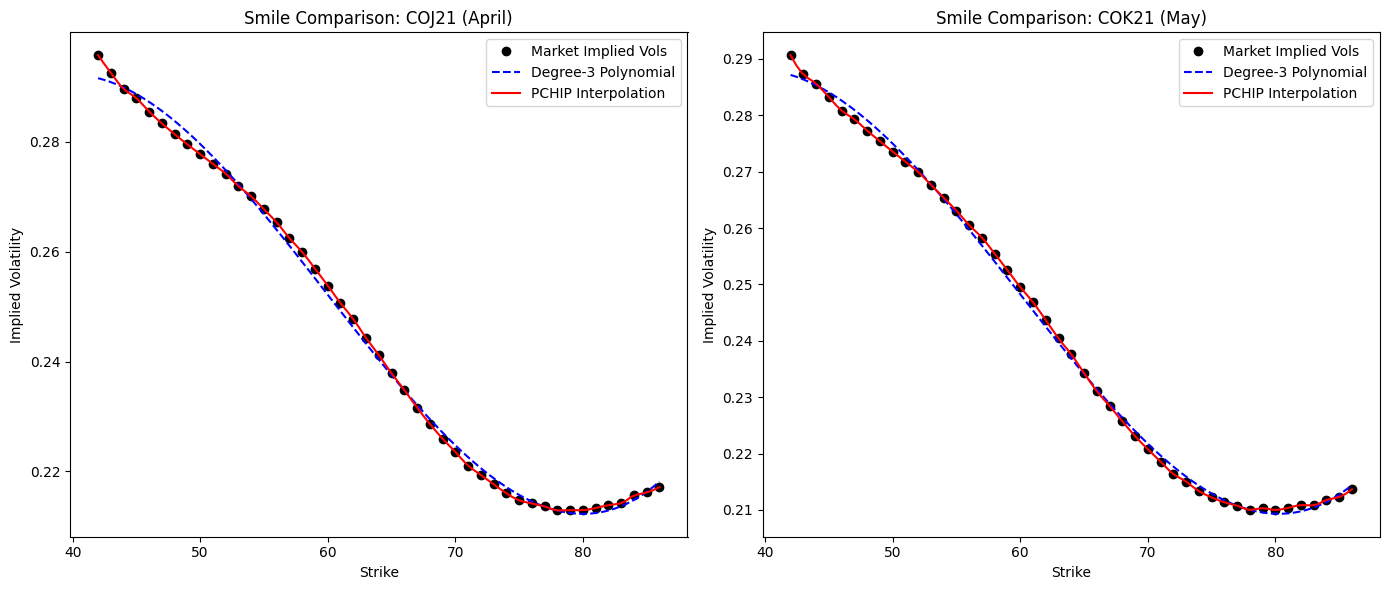

In [2]:

# =============================================================================
# PART 1: BASIC MATHEMATICAL FUNCTIONS
# =============================================================================

#i deleted this part bc it is in the function library

# =============================================================================
# PART 2: DATA LOADING AND DYNAMIC CORRELATION ESTIMATION
# =============================================================================

# 1. Load the clean parquet dataset


candidates = [Path.cwd() / 'unpivoted_bid_offer_train_clean.parquet', Path.cwd() / 'mes_donnees.csv']
path = next(p for p in candidates if p.exists())
df = pd.read_parquet(path) if path.suffix == '.parquet' else pd.read_csv(path)
print("Data file:", path.name)
df['date'] = pd.to_datetime(df['date'])
# SOFR is not published on US holidays: carry the last available rate forward
sofr = df.groupby('date')['sofr_rate'].first().ffill()
df['sofr_rate'] = df['date'].map(sofr)

valuation_date = pd.Timestamp('2020-01-06')
d = df[df['date'] == valuation_date]

c = d[d['underlying_ticker'] == 'COJ21 Comdty']   # April 2021 futures contract
c_K = d[d['underlying_ticker'] == 'COK21 Comdty'] # May 2021 futures contract

f1 = c['underlying_settlement'].iloc[0]
f2 = c_K['underlying_settlement'].iloc[0]


# 2. Dynamic estimation of the correlation rho up to the valuation date

# Compute rho as of the valuation date
rho = estimate_rho(df, valuation_date)
print("Estimated correlation rho:", rho)
# =============================================================================
# PART 3: SMILE CALIBRATION (Polynomial vs PCHIP Interpolation)
# =============================================================================

# --- April contract (COJ21) smile extraction ---
strikes_1, vols_1 = [], []
for _, ligne in c.iterrows():
    if ligne['option_type'] == 'Call' and ligne['option_bid'] > 0:
        K = ligne['strike']
        prix = (ligne['option_bid'] + ligne['option_ask']) / 2
        F = ligne['underlying_settlement']
        T = ligne['time_to_expiry_days'] / 365
        strikes_1.append(K)
        vols_1.append(vol_implicite(prix, F, K, T))

coef_poly_1 = np.polyfit(strikes_1, vols_1, 3) # Degree-3 polynomial (for visual comparison)
smile_apr21 = PchipInterpolator(strikes_1, vols_1, extrapolate=True) # Robust PCHIP interpolator


# --- May contract (COK21) smile extraction ---
strikes_2, vols_2 = [], []
for _, ligne in c_K.iterrows():
    if ligne['option_type'] == 'Call' and ligne['option_bid'] > 0:
        K = ligne['strike']
        prix = (ligne['option_bid'] + ligne['option_ask']) / 2
        F = ligne['underlying_settlement']
        T = ligne['time_to_expiry_days'] / 365
        strikes_2.append(K)
        vols_2.append(vol_implicite(prix, F, K, T))

coef_poly_2 = np.polyfit(strikes_2, vols_2, 3)
smile_may21 = PchipInterpolator(strikes_2, vols_2, extrapolate=True)

# =============================================================================
# PART 4: ASIAN BASKET PRICING (MOMENT-MATCHING METHOD)
# =============================================================================

# 1. Time-to-fixing fractions (thetas) for each business day of February 2021
date_depart = valuation_date.date()
thetas = []
for jour in range(1, 29): 
    dt = date(2021, 2, jour)
    if dt.weekday() < 5:  # Business days only (Monday to Friday)
        thetas.append((dt - date_depart).days / 365.0)

n_total = len(thetas)  # Total 20 business days
n1 = 18                # 18 days allocated to April contract
n2 = n_total - n1      # 2 days allocated to May contract

theta_1 = thetas[:n1]  
theta_2 = thetas[n1:]  

# 2. Basket Forward price average (F_avg)
w1 = n1 / n_total
w2 = n2 / n_total
F_avg = w1 * f1 + w2 * f2

# 3. Strike projections (Sticky-Moneyness mapping)
K_call = 78.0
K1_call = f1 * (K_call / F_avg)
K2_call = f2 * (K_call / F_avg)

# 4. Read volatilities from PCHIP curves
sigma1 = float(smile_apr21(K1_call))
sigma2 = float(smile_may21(K2_call))

# 5. Moment-matching engine (Variances and Cross-Covariance)


var_totale = variance_totale(sigma1, sigma2, theta_1, theta_2, f1, f2, w1, w2, n1, n2, rho)
v = math.sqrt(math.log(1 + (var_totale / (F_avg**2))))

T_final = 1.0 
prix_call = black_76(F_avg, K_call, v, 0, T_final, option_type='call')

# =============================================================================
# PART 5: PUT STRIKE SEARCH (DICHOTOMY FOR ZERO-COST COLLAR)
# =============================================================================

bas = 40.0
haut = 78.0
prix_put = 0  

# Bisection loop to find K_put such that Put Price equals Call Price
for _ in range(100):
    K_put = (bas + haut) / 2
    K_put_1 = f1 * (K_put / F_avg)
    K_put_2 = f2 * (K_put / F_avg)
    
    sigma_put_1 = float(smile_apr21(K_put_1))
    sigma_put_2 = float(smile_may21(K_put_2))
    
    var_totale_put = variance_totale(sigma_put_1, sigma_put_2, theta_1, theta_2, f1, f2, w1, w2, n1, n2, rho)
    v_put = math.sqrt(math.log(1 + (var_totale_put / (F_avg**2))))
    
    prix_put = black_76(F_avg, K_put, v_put, 0, T_final, option_type='put')
    
    if prix_put > prix_call:
        haut = K_put  # Put is too expensive -> lower the strike
    else:
        bas = K_put   # Put is too cheap -> raise the strike
        
    if abs(prix_put - prix_call) < 0.0001:
        break


# =============================================================================
# OUTPUTS AND COMPARATIVE PLOT (Polynomial vs PCHIP)
# =============================================================================
print("--- PRICING RESULTS (6 JANUARY 2020) ---")
print(f"Basket Forward price (F_avg): {F_avg:.2f} $")
print(f"Global basket volatility (v): {v:.4f}")
print(f"Theoretical Asian Call price at 78$: {prix_call:.4f} $")
print(f"Exact Put strike for Zero-Cost Collar: {K_put:.2f} $")
print(f"Verification - Call Price: {prix_call:.4f} $ | Put Price: {prix_put:.4f} $")

# Comparative plot: Polynomial degree 3 vs PCHIP
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
x_grid = np.linspace(min(strikes_1), max(strikes_1), 100)
plt.plot(strikes_1, vols_1, 'ko', label='Market Implied Vols')
plt.plot(x_grid, np.polyval(coef_poly_1, x_grid), 'b--', label='Degree-3 Polynomial')
plt.plot(x_grid, smile_apr21(x_grid), 'r-', label='PCHIP Interpolation')
plt.title('Smile Comparison: COJ21 (April)')
plt.xlabel('Strike')
plt.ylabel('Implied Volatility')
plt.legend()

plt.subplot(1, 2, 2)
x_grid_K = np.linspace(min(strikes_2), max(strikes_2), 100)
plt.plot(strikes_2, vols_2, 'ko', label='Market Implied Vols')
plt.plot(x_grid_K, np.polyval(coef_poly_2, x_grid_K), 'b--', label='Degree-3 Polynomial')
plt.plot(x_grid_K, smile_may21(x_grid_K), 'r-', label='PCHIP Interpolation')
plt.title('Smile Comparison: COK21 (May)')
plt.xlabel('Strike')
plt.ylabel('Implied Volatility')
plt.legend()

plt.tight_layout()
plt.show()

ICE Brent options are American but futures-style margined: the premium is not paid upfront but
marked to market daily, like the future itself. The holder therefore earns no interest by exercising early and receives the
same intrinsic value by keeping the option, so early exercise is never optimal and the American price equals the European one
(Lieu, 1990; Chen & Scott, 1993). This is why we invert the undiscounted Black-76 formula (r = 0, Asay 1982) and
treat the quotes as European.

In [3]:
# =============================================================================
# PART 6: FIXING SCHEDULE FROM THE ICE EXPIRY RULE (ANNEX B)
# =============================================================================



tickers = ['COJ21 Comdty', 'COK21 Comdty']
fixing_dates, n1_sched, n2_sched = build_fixing_schedule(2021, 2, tickers[0])

print("Apr21 futures expiry:", futures_expiry(tickers[0]).date())
print(f"Fixings: N = {len(fixing_dates)} | Apr21: {n1_sched} ({fixing_dates[0].date()} -> {fixing_dates[n1_sched-1].date()})"
      f" | May21: {n2_sched} ({fixing_dates[n1_sched].date()} -> {fixing_dates[-1].date()})")


theta_1_check, theta_2_check = fixing_thetas(fixing_dates, n1_sched, valuation_date)
assert (n1_sched, n2_sched) == (n1, n2)
assert np.allclose(theta_1_check, theta_1) and np.allclose(theta_2_check, theta_2)
print("Same schedule and thetas as the Main: OK")

Apr21 futures expiry: 2021-02-26
Fixings: N = 20 | Apr21: 18 (2021-02-01 -> 2021-02-24) | May21: 2 (2021-02-25 -> 2021-02-26)
Same schedule and thetas as the Main: OK


Apr21: 45 quotes in the Main -> 42 liquid OTM quotes kept, strikes 42 to 86
May21: 45 quotes in the Main -> 41 liquid OTM quotes kept, strikes 42 to 82


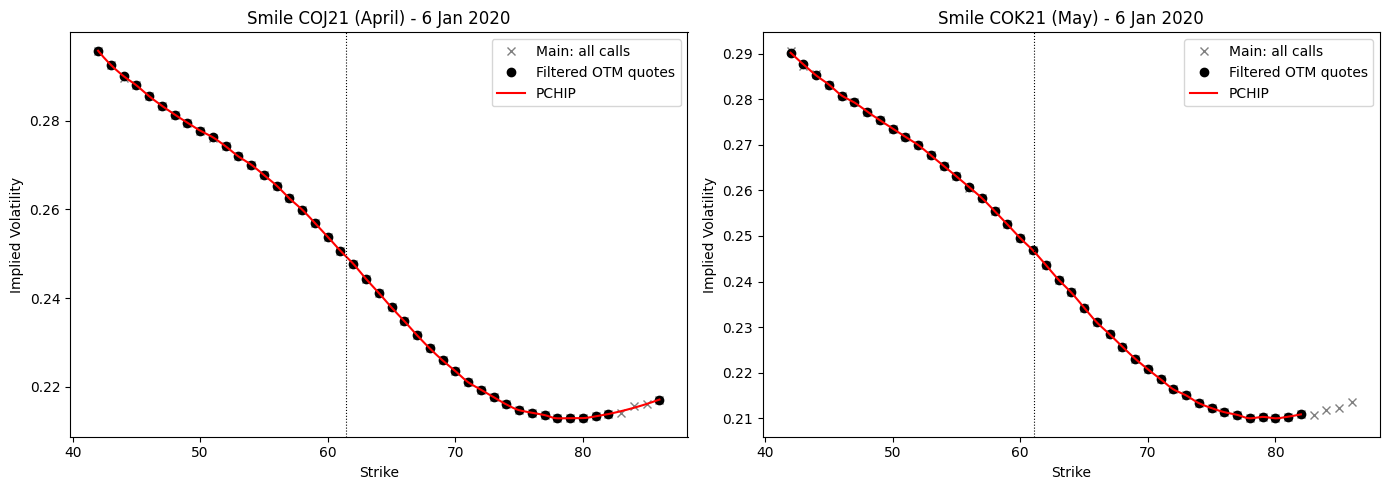

In [4]:
# =============================================================================
# PART 7: SMILE CALIBRATION WITH A LIQUIDITY FILTER
# =============================================================================


smile1_0 = get_smile(d, tickers[0])
smile2_0 = get_smile(d, tickers[1])
print(f"Apr21: {len(strikes_1)} quotes in the Main -> {len(smile1_0['strikes'])} liquid OTM quotes kept, "
      f"strikes {smile1_0['strikes'][0]:.0f} to {smile1_0['strikes'][-1]:.0f}")
print(f"May21: {len(strikes_2)} quotes in the Main -> {len(smile2_0['strikes'])} liquid OTM quotes kept, "
      f"strikes {smile2_0['strikes'][0]:.0f} to {smile2_0['strikes'][-1]:.0f}")

plt.figure(figsize=(14, 5))
for i, (smile, ks, vs, name) in enumerate([(smile1_0, strikes_1, vols_1, 'COJ21 (April)'),
                                            (smile2_0, strikes_2, vols_2, 'COK21 (May)')]):
    plt.subplot(1, 2, i + 1)
    grid = np.linspace(smile['strikes'][0], smile['strikes'][-1], 200)
    plt.plot(ks, vs, 'x', color='grey', label='Main: all calls')
    plt.plot(smile['strikes'], smile['vols'], 'ko', label='Filtered OTM quotes')
    plt.plot(grid, [read_vol(smile, k) for k in grid], 'r-', label='PCHIP')
    plt.axvline(smile['F'], color='k', ls=':', lw=0.8)
    plt.title(f'Smile {name} - 6 Jan 2020')
    plt.xlabel('Strike'); plt.ylabel('Implied Volatility'); plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# =============================================================================
# PART 8: PRICER AS FUNCTIONS (RHO AS AN ARGUMENT, SOFR DISCOUNTING)
# =============================================================================



# Sanity check: with the Main's smiles and no discounting, the functions give back the Main's call
main_smile1 = {'strikes': np.array(strikes_1), 'pchip': smile_apr21}
main_smile2 = {'strikes': np.array(strikes_2), 'pchip': smile_may21}
check_call = price_asian(K_call, 'call', f1, f2, main_smile1, main_smile2, rho, theta_1, theta_2)
assert abs(check_call - prix_call) < 1e-10
print(f"price_asian reproduces the Main's call: {check_call:.6f} = {prix_call:.6f}")

price_asian reproduces the Main's call: 1.096216 = 1.096216


In [6]:
# =============================================================================
# PART 9: PRICING AS OF 6 JANUARY 2020 WITH THE NEW PIPELINE
# =============================================================================

payment_date = fixing_dates[-1]                  # assumption: the collar settles on the last fixing date
D_0 = discount_factor(d, valuation_date, payment_date)

call_0 = price_asian(K_call, 'call', f1, f2, smile1_0, smile2_0, rho, theta_1, theta_2, D_0)
K_put_0 = solve_put_strike(call_0, f1, f2, smile1_0, smile2_0, rho, theta_1, theta_2, D_0)
put_0 = price_asian(K_put_0, 'put', f1, f2, smile1_0, smile2_0, rho, theta_1, theta_2, D_0)

# Discounting does not move K_put: both legs share the same D
K_put_undiscounted = solve_put_strike(call_0 / D_0, f1, f2, smile1_0, smile2_0, rho, theta_1, theta_2)

notional = 1_000_000
print("--- PRICING RESULTS (6 JANUARY 2020) ---")
print(f"Discount factor to {payment_date.date()}: {D_0:.5f} (SOFR {d['sofr_rate'].iloc[0]:.2f}%)")
print(f"{'':28}{'Main':>12}{'New':>12}")
print(f"{'Call(78) $/bbl':28}{prix_call:12.4f}{call_0:12.4f}")
print(f"{'K_put $':28}{K_put:12.4f}{K_put_0:12.4f}")
print(f"{'Put(K_put) $/bbl':28}{prix_put:12.4f}{put_0:12.4f}")
print(f"{'Call premium on 1M bbl $':28}{prix_call * notional:12,.0f}{call_0 * notional:12,.0f}")
print(f"K_put without discounting: {K_put_undiscounted:.6f} (same as with discounting)")

--- PRICING RESULTS (6 JANUARY 2020) ---
Discount factor to 2021-02-26: 0.98245 (SOFR 1.55%)
                                    Main         New
Call(78) $/bbl                    1.0962      1.0770
K_put $                          44.1678     44.1444
Put(K_put) $/bbl                  1.0963      1.0770
Call premium on 1M bbl $       1,096,216   1,076,975
K_put without discounting: 44.144409 (same as with discounting)


In [7]:
# =============================================================================
# PART 10: CALIBRATION ON EVERY DAY OF THE TRAINING SET
# =============================================================================

futures_prices = (
    df[['date', 'underlying_ticker', 'underlying_settlement']]
    .drop_duplicates(subset=['date', 'underlying_ticker'])
    .pivot(index='date', columns='underlying_ticker', values='underlying_settlement')
    .sort_index()
)
futures_prices.index = pd.to_datetime(futures_prices.index)
log_returns = np.log(futures_prices[tickers]).diff()


calibration = []
last_smiles = {}
smiles_by_day = {}

for day, day_data in df.groupby('date'):
    day = pd.Timestamp(day)
    if day > fixing_dates[-1]:
        break

    smiles, stale = {}, {}
    for contract in tickers:
        smile = get_smile(day_data, contract)
        stale[contract] = smile is None
        if smile is None:
            smile = last_smiles.get(contract)     # not enough liquid quotes: keep yesterday's smile
        last_smiles[contract] = smile
        smiles[contract] = smile
        smiles_by_day[day] = smiles

    f1_t, f2_t = futures_prices.at[day, tickers[0]], futures_prices.at[day, tickers[1]]
    rho_t = estimate_rho_rolling(log_returns, tickers, day)
    row = {'date': day, 'f1': f1_t, 'f2': f2_t, 'rho': rho_t,
           'n_quotes_1': 0 if stale[tickers[0]] else len(smiles[tickers[0]]['strikes']),
           'n_quotes_2': 0 if stale[tickers[1]] else len(smiles[tickers[1]]['strikes']),
           'stale_1': stale[tickers[0]], 'stale_2': stale[tickers[1]],
           'has_bid_ask': day_data['option_bid'].notna().any()}

    if smiles[tickers[0]] is not None and np.isfinite(f1_t):
        row['atm_vol_1'] = read_vol(smiles[tickers[0]], f1_t)
    if smiles[tickers[1]] is not None:
        row['atm_vol_2'] = read_vol(smiles[tickers[1]], f2_t)

    # The moment-matching formulas assume no fixing has happened yet: during February 2021
    # the known fixings must be handled separately (Step 7)
    if day < fixing_dates[0]:
        D_t = discount_factor(day_data, day, payment_date)
        th1, th2 = fixing_thetas(fixing_dates, n1_sched, day)
        call_t = price_asian(K_call, 'call', f1_t, f2_t, smiles[tickers[0]], smiles[tickers[1]], rho_t, th1, th2, D_t)
        put_t = price_asian(K_put_0, 'put', f1_t, f2_t, smiles[tickers[0]], smiles[tickers[1]], rho_t, th1, th2, D_t)
        F_avg_t = (n1_sched * f1_t + n2_sched * f2_t) / (n1_sched + n2_sched)
        row.update({'D': D_t, 'F_avg': F_avg_t,
                    'sigma1_call': read_vol(smiles[tickers[0]], f1_t * K_call / F_avg_t),
                    'sigma1_put': read_vol(smiles[tickers[0]], f1_t * K_put_0 / F_avg_t),
                    'call': call_t, 'put': put_t,
                    'collar_value': notional * (put_t - call_t)})   # market maker: long put, short call
    calibration.append(row)

calibration = pd.DataFrame(calibration).set_index('date')
print(f"Calibrated days: {len(calibration)} ({calibration.index[0].date()} -> {calibration.index[-1].date()})")
print(f"Days with a stale smile: Apr21 {calibration['stale_1'].sum()}, May21 {calibration['stale_2'].sum()}")
print(f"Days priced from settlement prices only (no bid/ask): {(~calibration['has_bid_ask']).sum()}")
print(f"Collar value at inception: {calibration['collar_value'].iloc[0]:,.2f} $ (zero cost)")
display(calibration.drop(columns=['stale_1', 'stale_2', 'has_bid_ask']).iloc[::20].round(4))

Calibrated days: 297 (2020-01-06 -> 2021-02-26)
Days with a stale smile: Apr21 6, May21 0
Days priced from settlement prices only (no bid/ask): 192
Collar value at inception: -0.00 $ (zero cost)


,f1,f2,rho,n_quotes_1,n_quotes_2,atm_vol_1,atm_vol_2,D,F_avg,sigma1_call,sigma1_put,call,put,collar_value
date,,,,,,,,,,,,,,
2020-01-06,61.40,61.05,0.9900,42,41,0.2495,0.2467,0.9824,61.365,0.2129,0.2897,1.0770,1.0770,-8.000000e-04
2020-02-03,54.34,54.34,0.9995,34,33,0.2670,0.2616,0.9832,54.340,0.2287,0.2830,0.3663,1.8572,1.490903e+06
2020-03-02,52.27,52.35,0.9996,33,33,0.2656,0.2598,0.9844,52.278,0.2419,0.2800,0.2623,2.0688,1.806507e+06
2020-03-30,39.22,39.58,0.9998,34,35,0.4369,0.4206,0.9999,39.256,0.3951,0.4117,0.2367,9.0469,8.810173e+06
2020-04-28,33.71,34.25,0.9998,31,31,0.5070,0.4893,0.9999,33.764,0.4871,0.4803,0.2120,12.9668,1.275473e+07
2020-05-26,40.14,40.49,0.9998,37,38,0.4079,0.3995,0.9995,40.175,0.3874,0.3904,0.1378,7.7010,7.563207e+06
2020-06-23,43.77,43.95,0.9997,9,10,0.4366,0.4261,0.9995,43.788,0.4147,0.4348,0.3011,6.1981,5.897003e+06
2020-07-21,45.72,45.91,0.9997,9,10,0.3827,0.3776,0.9993,45.739,0.3558,0.3947,0.1256,4.4867,4.361117e+06
2020-08-18,47.84,48.06,0.9997,10,10,0.3680,0.3684,0.9995,47.862,0.3464,0.3970,0.1098,3.3798,3.269948e+06


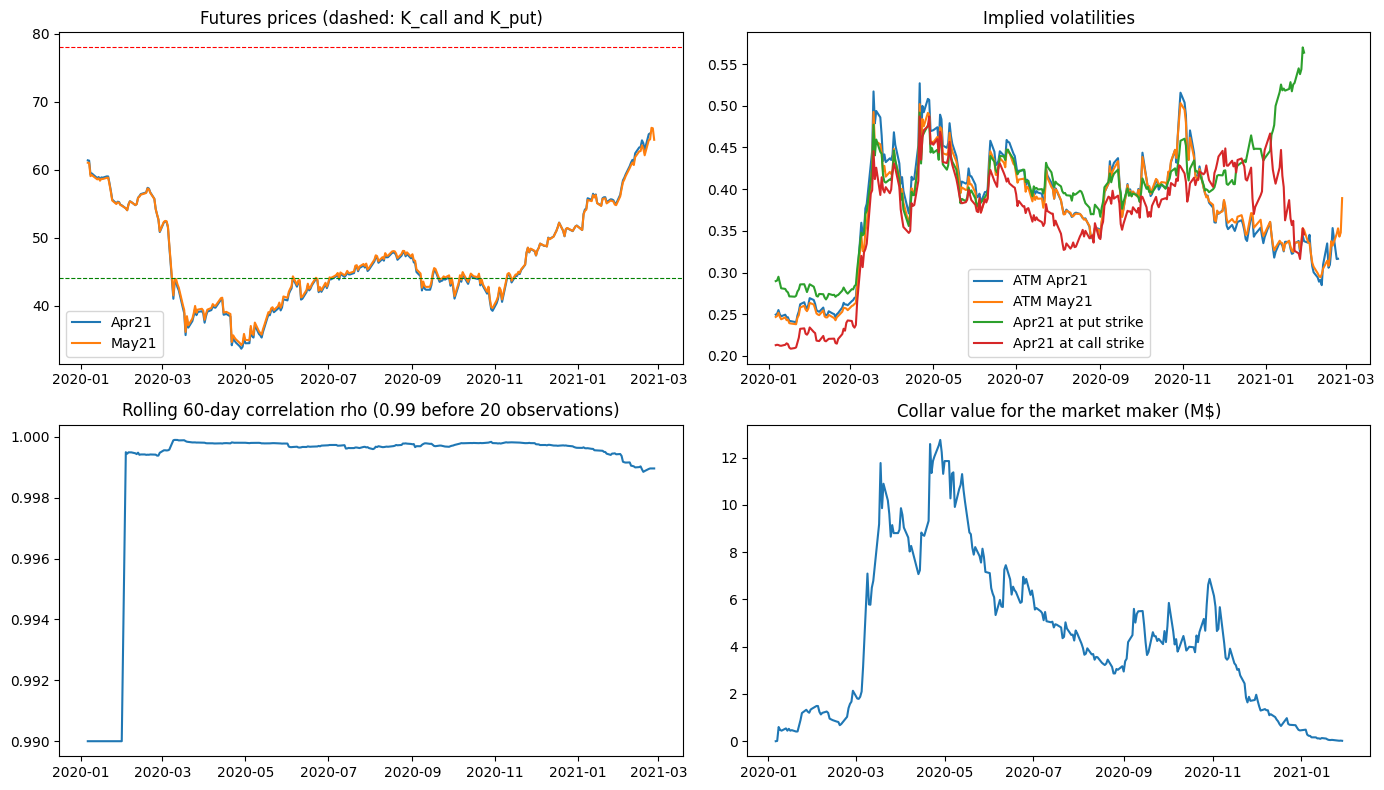

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))

ax[0, 0].plot(calibration[['f1', 'f2']])
ax[0, 0].axhline(K_call, color='r', ls='--', lw=0.8); ax[0, 0].axhline(K_put_0, color='g', ls='--', lw=0.8)
ax[0, 0].set_title('Futures prices (dashed: K_call and K_put)'); ax[0, 0].legend(['Apr21', 'May21'])

ax[0, 1].plot(calibration[['atm_vol_1', 'atm_vol_2', 'sigma1_put', 'sigma1_call']])
ax[0, 1].set_title('Implied volatilities'); ax[0, 1].legend(['ATM Apr21', 'ATM May21', 'Apr21 at put strike', 'Apr21 at call strike'])

ax[1, 0].plot(calibration['rho'])
ax[1, 0].set_title('Rolling 60-day correlation rho (0.99 before 20 observations)')

ax[1, 1].plot(calibration['collar_value'] / 1e6)
ax[1, 1].set_title('Collar value for the market maker (M$)')

plt.tight_layout()
plt.show()

In [9]:
# =============================================================================
# PART 11: GREEKS OF THE COLLAR AND OF THE LISTED OPTIONS
# =============================================================================

# Check of the bump scheme on a European option, where the exact greeks are known
F_test, K_test, sig_test, T_test, h_test = 61.4, 45.0, 0.29, 1.13, 0.01 * 61.4
up, mid, down = (black_76(F_test + s, K_test, sig_test, 0, T_test, 'put') for s in (h_test, 0, -h_test))
delta_exact, gamma_exact, _ = black_76_greeks(F_test, K_test, sig_test, T_test, 'put')
print(f"Bump check  | delta {(up - down) / (2 * h_test):.6f} vs {delta_exact:.6f}"
      f" | gamma {(up - 2 * mid + down) / h_test**2:.6f} vs {gamma_exact:.6f}")

Bump check  | delta -0.122638 vs -0.122585 | gamma 0.010730 vs 0.010728


In [10]:
# =============================================================================
# PART 12: DAILY DELTA AND GAMMA OF THE COLLAR
# =============================================================================

greeks = []
for day, smiles in smiles_by_day.items():
    if day >= fixing_dates[0]:
        break
    f1_t, f2_t = calibration.at[day, 'f1'], calibration.at[day, 'f2']
    th1, th2 = fixing_thetas(fixing_dates, n1_sched, day)
    V, delta_c, gamma_c = collar_greeks(f1_t, f2_t, smiles[tickers[0]], smiles[tickers[1]],
                                        calibration.at[day, 'rho'], th1, th2, calibration.at[day, 'D'], K_put_0)
    greeks.append({'date': day, 'value': V, 'delta': delta_c, 'gamma': gamma_c})

greeks = pd.DataFrame(greeks).set_index('date')

# Daily P&L of a delta-only hedge explained by gamma: 1/2 * Gamma * (dF)^2, with dF the next-day move
dF = futures_prices[tickers[0]].shift(-1).reindex(greeks.index) - calibration['f1'].reindex(greeks.index)
greeks['gamma_pnl'] = 0.5 * greeks['gamma'] * dF**2

print(f"Days: {len(greeks)} | gamma > 0 on {(greeks['gamma'] > 0).sum()} days, < 0 on {(greeks['gamma'] < 0).sum()} days")
print(f"Gamma range: {greeks['gamma'].min():,.0f} to {greeks['gamma'].max():,.0f} bbl per $")
print(f"Largest daily 1/2 Gamma dF^2: {greeks['gamma_pnl'].abs().max():,.0f} $ on {greeks['gamma_pnl'].abs().idxmax().date()}")
print(f"Mean of (1/2 Gamma dF^2)^2: {(greeks['gamma_pnl']**2).mean():,.0f} $^2")
display(greeks.iloc[::20].round(0))

Days: 277 | gamma > 0 on 264 days, < 0 on 13 days
Gamma range: -8,195 to 45,550 bbl per $
Largest daily 1/2 Gamma dF^2: 511,652 $ on 2020-03-06
Mean of (1/2 Gamma dF^2)^2: 1,500,410,166 $^2


,value,delta,gamma,gamma_pnl
date,,,,
2020-01-06,-0.0,-269386.0,-8195.0,-10.0
2020-02-03,1490903.0,-260385.0,6434.0,235.0
2020-03-02,1806507.0,-275303.0,11731.0,115.0
2020-03-30,8810173.0,-591847.0,19798.0,951.0
2020-04-28,12754733.0,-704433.0,19375.0,815.0
2020-05-26,7563207.0,-578973.0,24755.0,7921.0
2020-06-23,5897003.0,-496089.0,18317.0,28048.0
2020-07-21,4361117.0,-423706.0,23077.0,74.0
2020-08-18,3269948.0,-360127.0,22147.0,40.0


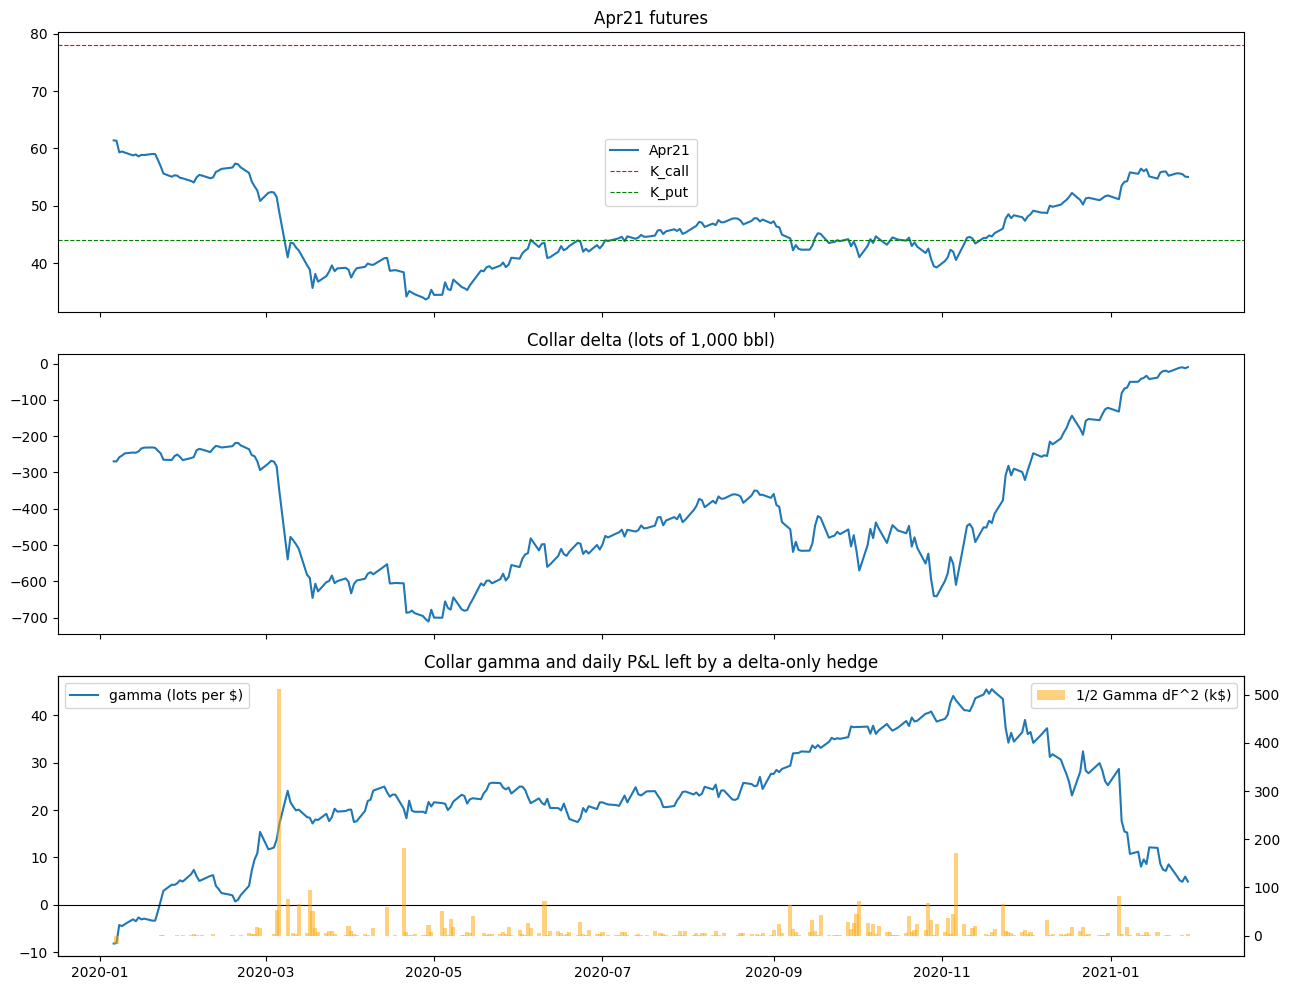

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

ax[0].plot(calibration['f1'].reindex(greeks.index), label='Apr21')
ax[0].axhline(K_call, color='r', ls='--', lw=0.8, label='K_call')
ax[0].axhline(K_put_0, color='g', ls='--', lw=0.8, label='K_put')
ax[0].set_title('Apr21 futures'); ax[0].legend()

ax[1].plot(greeks['delta'] / 1000)
ax[1].set_title('Collar delta (lots of 1,000 bbl)')

ax[2].plot(greeks['gamma'] / 1000, label='gamma (lots per $)')
ax[2].axhline(0, color='k', lw=0.8)
ax2 = ax[2].twinx()
ax2.bar(greeks.index, greeks['gamma_pnl'] / 1e3, color='orange', alpha=0.5, width=1.5, label='1/2 Gamma dF^2 (k$)')
ax[2].set_title('Collar gamma and daily P&L left by a delta-only hedge')
ax[2].legend(loc='upper left'); ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [12]:
# =============================================================================
# PART 13: BACKTEST OF THE DELTA-GAMMA HEDGE WITH ONE FIXED OPTION (APR21 PUT 45)
# =============================================================================

# Spreads used on days without bid/ask: median observed spread on the days where it exists
apr21 = df[df['underlying_ticker'] == tickers[0]]
put45 = apr21[(apr21['option_type'] == 'Put') & (apr21['strike'] == 45)].dropna(subset=['option_bid', 'option_ask'])
half_spread_opt = ((put45['option_ask'] - put45['option_bid']) / 2).median()
fut_quotes = apr21.drop_duplicates('date').dropna(subset=['underlying_bid', 'underlying_ask'])
half_spread_fut = ((fut_quotes['underlying_ask'] - fut_quotes['underlying_bid']) / 2).median()
print(f"Half spreads used without quotes: Put 45 {half_spread_opt:.3f} $ | Apr21 futures {half_spread_fut:.3f} $")

hedge_option = ('Put', 45.0)
bt_gamma = backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0], hedge_option,
                                use_gamma=True, half_spread_opt=half_spread_opt, half_spread_fut=half_spread_fut)
bt_delta = backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0], hedge_option,
                                use_gamma=False, half_spread_opt=half_spread_opt, half_spread_fut=half_spread_fut)

summary = pd.DataFrame({
    name: {'mean P&L^2 ($^2)': (bt['pnl'].iloc[1:]**2).mean(),
           'RMS daily P&L ($)': np.sqrt((bt['pnl'].iloc[1:]**2).mean()),
           'worst day ($)': bt['pnl'].min(),
           'best day ($)': bt['pnl'].max(),
           'total costs ($)': bt['cost'].sum(),
           'final portfolio ($)': bt['portfolio'].iloc[-1]}
    for name, bt in [('delta only', bt_delta), ('delta-gamma Put 45', bt_gamma)]})
display(summary.round(0))

Half spreads used without quotes: Put 45 0.120 $ | Apr21 futures 0.030 $


,delta only,delta-gamma Put 45
mean P&L^2 ($^2),2.239811e+10,797514450.0
RMS daily P&L ($),1.496600e+05,28240.0
worst day ($),-5.686290e+05,-167269.0
best day ($),1.216851e+06,193515.0
total costs ($),1.457340e+05,1136332.0
final portfolio ($),8.065980e+05,-1199099.0


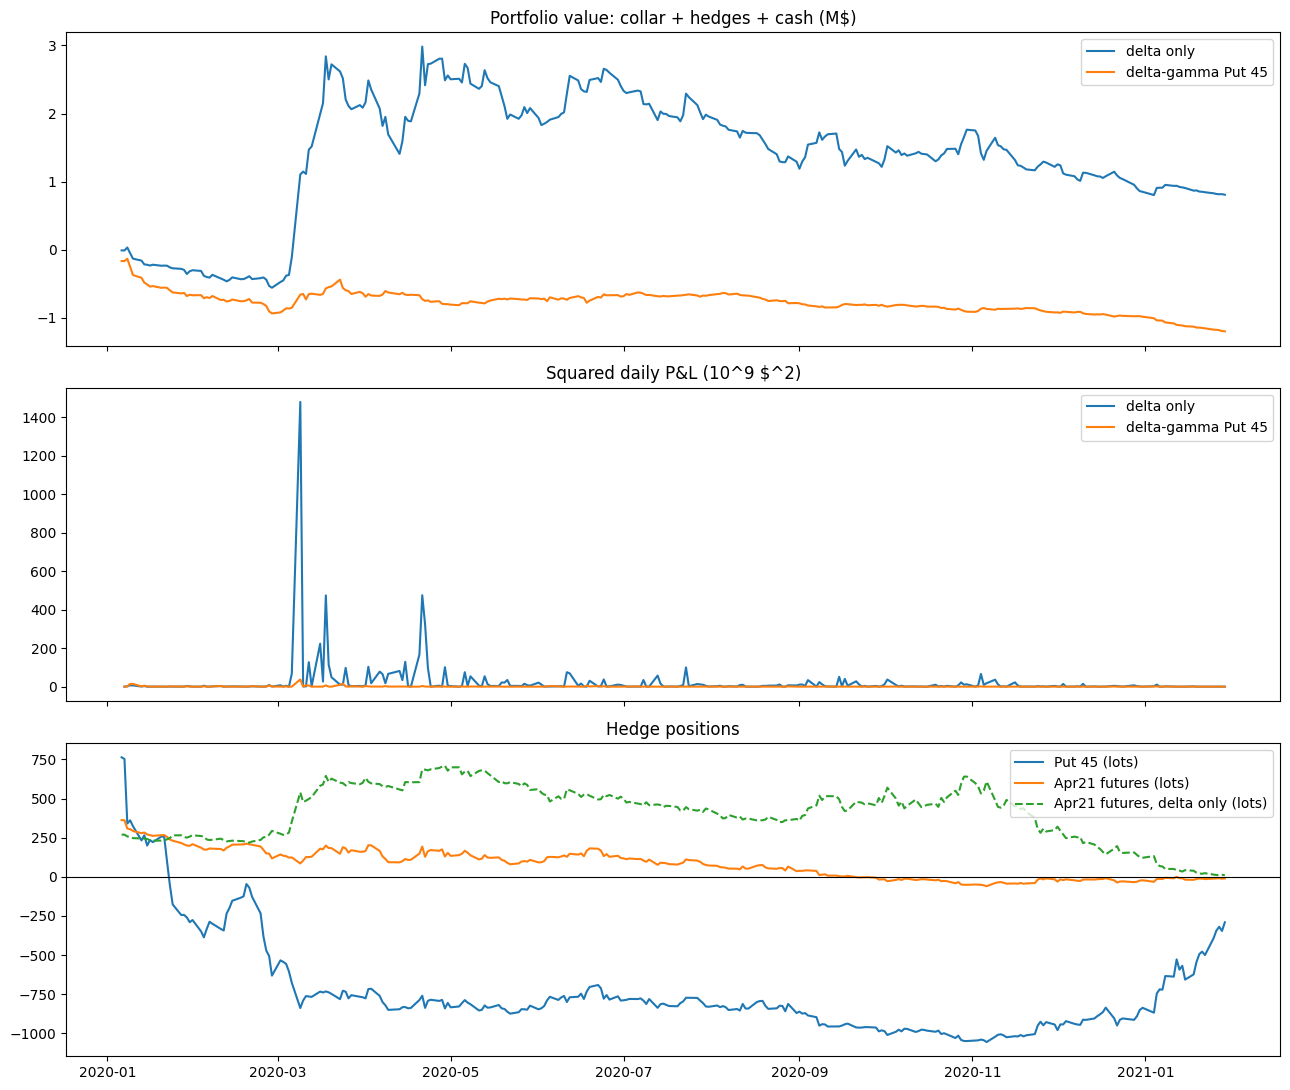

In [13]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

for name, bt in [('delta only', bt_delta), ('delta-gamma Put 45', bt_gamma)]:
    ax[0].plot(bt['portfolio'] / 1e6, label=name)
    ax[1].plot(bt['pnl'].iloc[1:]**2 / 1e9, label=name)
ax[0].set_title('Portfolio value: collar + hedges + cash (M$)'); ax[0].legend()
ax[1].set_title('Squared daily P&L (10^9 $^2)'); ax[1].legend()

ax[2].plot(bt_gamma['n_options'] / 1000, label='Put 45 (lots)')
ax[2].plot(bt_gamma['q_futures'] / 1000, label='Apr21 futures (lots)')
ax[2].plot(bt_delta['q_futures'] / 1000, ls='--', label='Apr21 futures, delta only (lots)')
ax[2].axhline(0, color='k', lw=0.8)
ax[2].set_title('Hedge positions'); ax[2].legend()

plt.tight_layout()
plt.show()

In [14]:
# =============================================================================
# PART 14: DELTA-GAMMA HEDGE WITH A REBALANCING BAND ON THE OPTIONS
# =============================================================================

bands = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
bt_bands = {band: backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0], hedge_option,
                                       half_spread_opt=half_spread_opt, half_spread_fut=half_spread_fut, band=band)
            for band in bands}

def metrics(bt):
    return {'mean P&L^2 ($^2)': (bt['pnl'].iloc[1:]**2).mean(),
            'RMS daily P&L ($)': np.sqrt((bt['pnl'].iloc[1:]**2).mean()),
            'worst day ($)': bt['pnl'].min(),
            'option trades': int(bt['options_traded'].sum()),
            'total costs ($)': bt['cost'].sum(),
            'final portfolio ($)': bt['portfolio'].iloc[-1]}

band_summary = pd.DataFrame({f'band {b:.0%}': metrics(bt) for b, bt in bt_bands.items()}
                            | {'delta only': metrics(bt_delta)}).T
display(band_summary.round(0))

,mean P&L^2 ($^2),RMS daily P&L ($),worst day ($),option trades,total costs ($),final portfolio ($)
band 0%,7.975144e+08,28240.0,-167269.0,277.0,1136332.0,-1199099.0
band 5%,8.131177e+08,28515.0,-167269.0,82.0,874318.0,-953602.0
band 10%,8.322837e+08,28849.0,-167269.0,47.0,724923.0,-867592.0
band 20%,9.715524e+08,31170.0,-167269.0,26.0,582117.0,-707095.0
band 30%,1.444958e+09,38013.0,-167269.0,22.0,572944.0,-462456.0
band 50%,2.147539e+09,46342.0,-167269.0,15.0,540917.0,-102673.0
delta only,2.239811e+10,149660.0,-568629.0,0.0,145734.0,806598.0


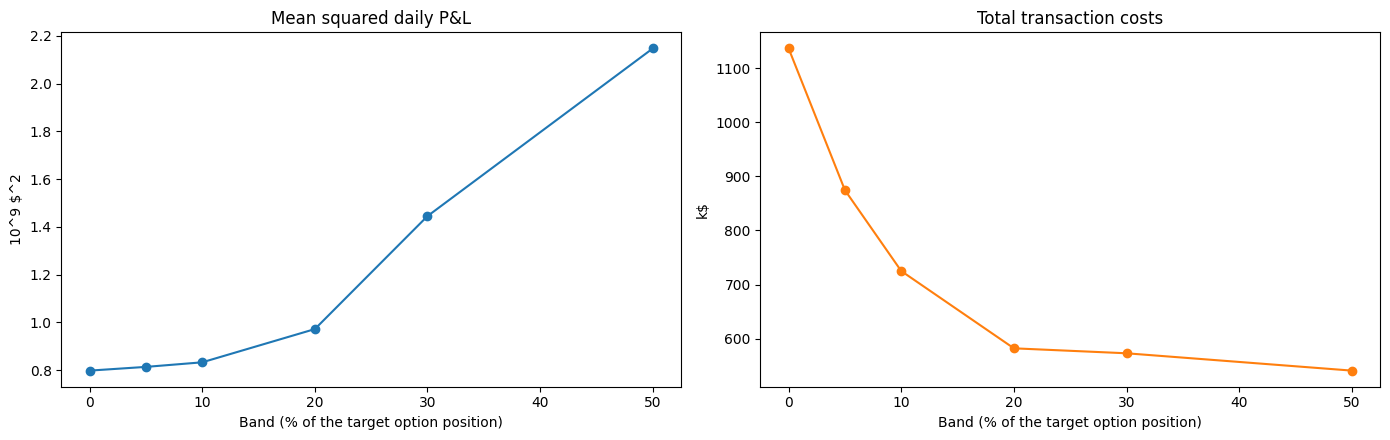

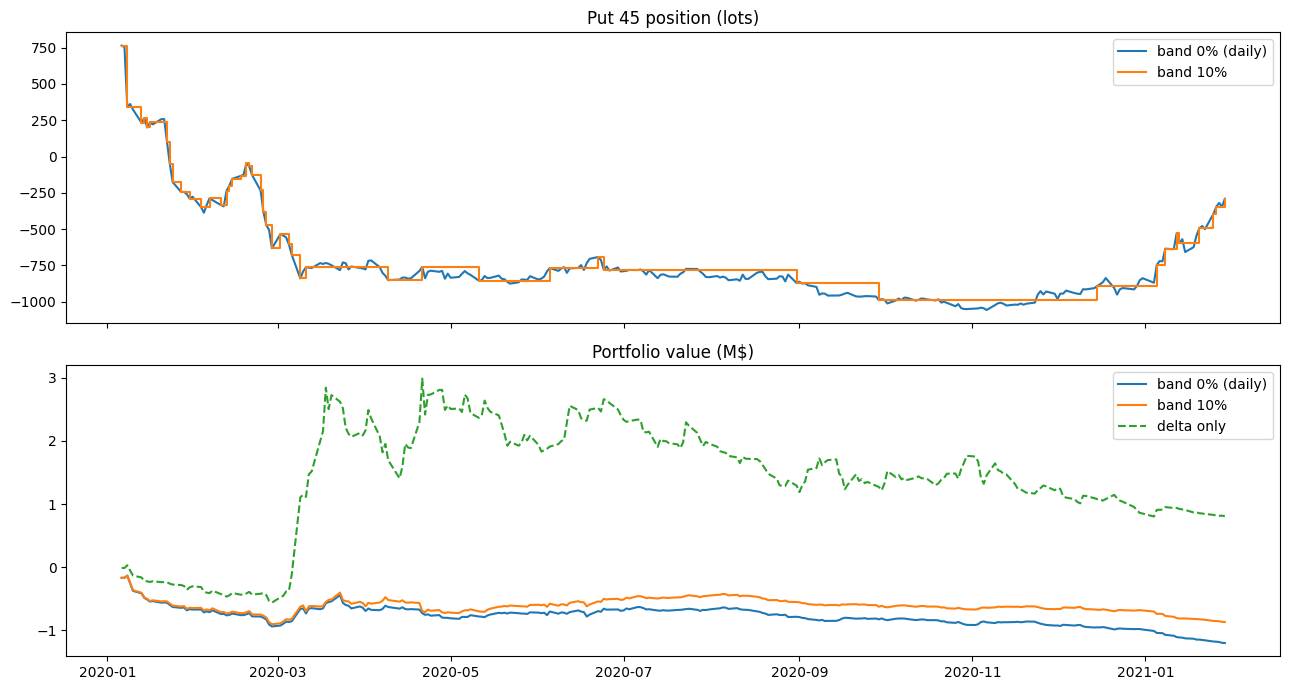

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
x = [b * 100 for b in bands]
ax[0].plot(x, band_summary['mean P&L^2 ($^2)'].iloc[:-1] / 1e9, 'o-')
ax[0].set_xlabel('Band (% of the target option position)'); ax[0].set_ylabel('10^9 $^2')
ax[0].set_title('Mean squared daily P&L')
ax[1].plot(x, band_summary['total costs ($)'].iloc[:-1] / 1e3, 'o-', color='tab:orange')
ax[1].set_xlabel('Band (% of the target option position)'); ax[1].set_ylabel('k$')
ax[1].set_title('Total transaction costs')
plt.tight_layout()
plt.show()

chosen_band = 0.10
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(bt_bands[0.0]['n_options'] / 1000, label='band 0% (daily)')
ax[0].plot(bt_bands[chosen_band]['n_options'] / 1000, drawstyle='steps-post', label=f'band {chosen_band:.0%}')
ax[0].set_title('Put 45 position (lots)'); ax[0].legend()
ax[1].plot(bt_bands[0.0]['portfolio'] / 1e6, label='band 0% (daily)')
ax[1].plot(bt_bands[chosen_band]['portfolio'] / 1e6, label=f'band {chosen_band:.0%}')
ax[1].plot(bt_delta['portfolio'] / 1e6, ls='--', label='delta only')
ax[1].set_title('Portfolio value (M$)'); ax[1].legend()
plt.tight_layout()
plt.show()

In [16]:
# =============================================================================
# PART 15: HEDGING OPTION CHOSEN FROM THE SIGN OF THE COLLAR GAMMA
# =============================================================================

# Regression check: the fixed Put 45 hedge gives the same results as in Part 14
check = backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0], hedge_option,
                             half_spread_opt=half_spread_opt, half_spread_fut=half_spread_fut, band=0.10)
assert np.allclose(check['pnl'], bt_bands[0.10]['pnl'])
print("Fixed Put 45: same P&L as Part 14")

bt_auto = {band: backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0], 'auto',
                                      half_spread_opt=half_spread_opt, half_spread_fut=half_spread_fut,
                                      band=band, K_put=K_put_0, K_call=K_call)
           for band in [0.0, 0.05, 0.10, 0.20]}

auto_summary = pd.DataFrame({f'Put 45, band {b:.0%}': metrics(bt_bands[b]) for b in [0.0, 0.05, 0.10, 0.20]}
                            | {f'auto, band {b:.0%}': metrics(bt) for b, bt in bt_auto.items()}
                            | {'delta only': metrics(bt_delta)}).T
display(auto_summary.round(0))

# Which option is used, and when
switches = bt_auto[0.10]['option'].ne(bt_auto[0.10]['option'].shift())
display(bt_auto[0.10].loc[switches, ['option', 'n_options', 'cost']].assign(n_options=lambda x: x['n_options'] / 1000)
        .rename(columns={'n_options': 'lots'}).round(1))

Fixed Put 45: same P&L as Part 14


,mean P&L^2 ($^2),RMS daily P&L ($),worst day ($),option trades,total costs ($),final portfolio ($)
"Put 45, band 0%",7.975144e+08,28240.0,-167269.0,277.0,1136332.0,-1199099.0
"Put 45, band 5%",8.131177e+08,28515.0,-167269.0,82.0,874318.0,-953602.0
"Put 45, band 10%",8.322837e+08,28849.0,-167269.0,47.0,724923.0,-867592.0
"Put 45, band 20%",9.715524e+08,31170.0,-167269.0,26.0,582117.0,-707095.0
"auto, band 0%",7.360880e+08,27131.0,-122069.0,277.0,977008.0,-985409.0
"auto, band 5%",7.487222e+08,27363.0,-122069.0,79.0,707935.0,-733379.0
"auto, band 10%",7.747488e+08,27834.0,-127943.0,46.0,567947.0,-656929.0
"auto, band 20%",9.181963e+08,30302.0,-114257.0,26.0,441990.0,-512640.0
delta only,2.239811e+10,149660.0,-568629.0,0.0,145734.0,806598.0


,option,lots,cost
date,,,
2020-01-06,Call 80,498.2,67647.2
2020-01-23,Put 45,-51.9,20139.3


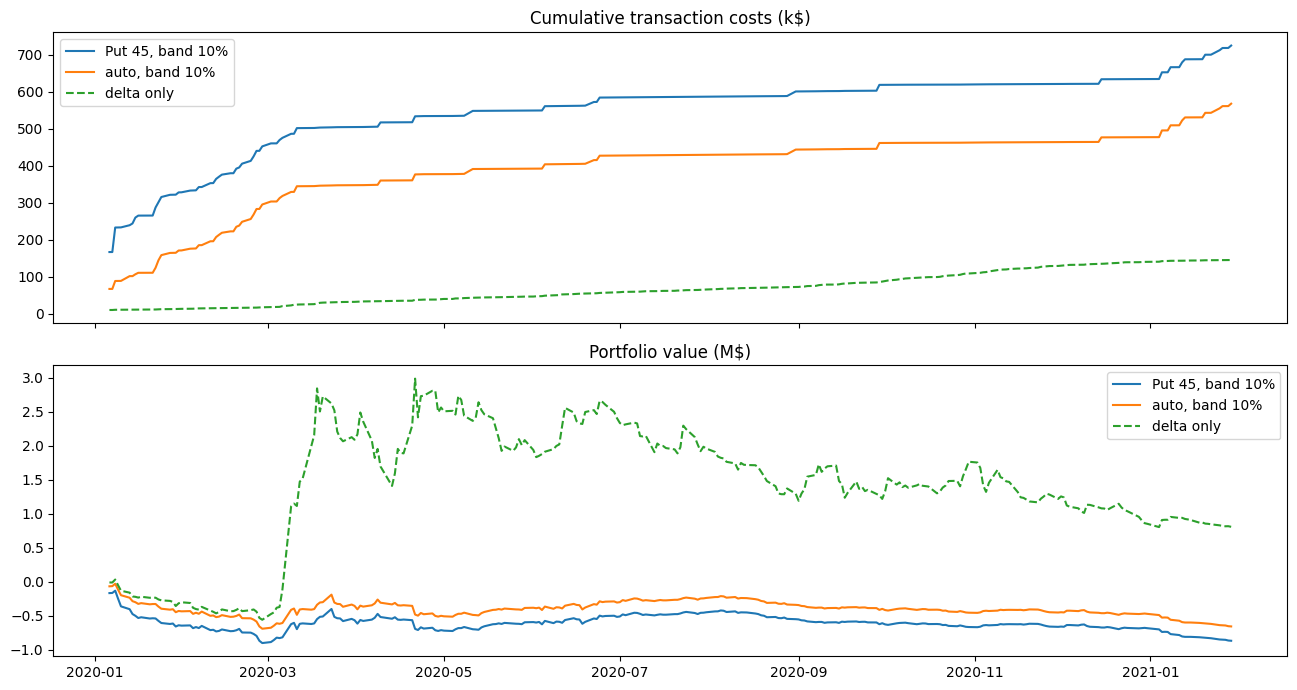

In [17]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(bt_bands[0.10]['cost'].cumsum() / 1e3, label='Put 45, band 10%')
ax[0].plot(bt_auto[0.10]['cost'].cumsum() / 1e3, label='auto, band 10%')
ax[0].plot(bt_delta['cost'].cumsum() / 1e3, ls='--', label='delta only')
ax[0].set_title('Cumulative transaction costs (k$)'); ax[0].legend()
ax[1].plot(bt_bands[0.10]['portfolio'] / 1e6, label='Put 45, band 10%')
ax[1].plot(bt_auto[0.10]['portfolio'] / 1e6, label='auto, band 10%')
ax[1].plot(bt_delta['portfolio'] / 1e6, ls='--', label='delta only')
ax[1].set_title('Portfolio value (M$)'); ax[1].legend()
plt.tight_layout()
plt.show()

In [18]:
# =============================================================================
# PART 16: SENSITIVITY TO THE SPREADS ASSUMED ON DAYS WITHOUT BID/ASK
# =============================================================================

strategies = {'delta only': dict(hedge_option=hedge_option, use_gamma=False),
              'Put 45, band 0%': dict(hedge_option=hedge_option, band=0.0),
              'Put 45, band 5%': dict(hedge_option=hedge_option, band=0.05),
              'Put 45, band 10%': dict(hedge_option=hedge_option, band=0.10),
              'auto, band 0%': dict(hedge_option='auto', band=0.0),
              'auto, band 5%': dict(hedge_option='auto', band=0.05),
              'auto, band 10%': dict(hedge_option='auto', band=0.10)}
multipliers = [0.5, 1.0, 2.0]

rows = []
for m in multipliers:
    for name, params in strategies.items():
        bt = backtest_delta_gamma(greeks, df, smiles_by_day, futures_prices, tickers[0],
                                  half_spread_opt=m * half_spread_opt, half_spread_fut=m * half_spread_fut,
                                  K_put=K_put_0, K_call=K_call, **params)
        rows.append({'spread x': m, 'strategy': name, **metrics(bt)})
sensitivity = pd.DataFrame(rows)

metric_table = sensitivity.pivot(index='strategy', columns='spread x', values='mean P&L^2 ($^2)').loc[list(strategies)]
cost_table = sensitivity.pivot(index='strategy', columns='spread x', values='total costs ($)').loc[list(strategies)]
print("Mean squared daily P&L (10^8 $^2)")
display((metric_table / 1e8).round(2))
print("Total transaction costs (k$)")
display((cost_table / 1e3).round(0))
print("Best strategy for each spread assumption:")
print(metric_table.idxmin())

Mean squared daily P&L (10^8 $^2)


spread x,0.5,1.0,2.0
strategy,,,
delta only,224.05,223.98,223.85
"Put 45, band 0%",7.87,7.98,8.33
"Put 45, band 5%",8.04,8.13,8.42
"Put 45, band 10%",8.32,8.32,8.44
"auto, band 0%",7.25,7.36,7.71
"auto, band 5%",7.40,7.49,7.77
"auto, band 10%",7.74,7.75,7.87


Total transaction costs (k$)


spread x,0.5,1.0,2.0
strategy,,,
delta only,96.0,146.0,244.0
"Put 45, band 0%",911.0,1136.0,1586.0
"Put 45, band 5%",754.0,874.0,1115.0
"Put 45, band 10%",637.0,725.0,901.0
"auto, band 0%",752.0,977.0,1427.0
"auto, band 5%",587.0,708.0,949.0
"auto, band 10%",480.0,568.0,744.0


Best strategy for each spread assumption:
spread x
0.5    auto, band 0%
1.0    auto, band 0%
2.0    auto, band 0%
dtype: object
